In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [8]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if images:
        print(root, "Images:", len(images))

/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames/Deepfakes Images: 5000
/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames/Face2Face Images: 5000
/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames/FaceShifter Images: 5000
/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames/FaceSwap Images: 5000
/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames/NeuralTextures Images: 5000
/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames/Original Images: 5000


In [7]:
import os

print(os.listdir("/kaggle/input"))


[]


In [9]:
import os

base_path = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames"

for folder in os.listdir(base_path):
    folder_path = os.path.join(base_path, folder)
    if os.path.isdir(folder_path):
        print("\n", folder)
        print("Subfolders:", os.listdir(folder_path)[:5])
        print("Sample files:", [
            f for f in os.listdir(folder_path)[:5]
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])


 Deepfakes
Subfolders: ['000_003_f0.jpg', '000_003_f1.jpg', '000_003_f2.jpg', '000_003_f3.jpg', '000_003_f4.jpg']
Sample files: ['000_003_f0.jpg', '000_003_f1.jpg', '000_003_f2.jpg', '000_003_f3.jpg', '000_003_f4.jpg']

 Face2Face
Subfolders: ['000_003_f0.jpg', '000_003_f1.jpg', '000_003_f2.jpg', '000_003_f3.jpg', '000_003_f4.jpg']
Sample files: ['000_003_f0.jpg', '000_003_f1.jpg', '000_003_f2.jpg', '000_003_f3.jpg', '000_003_f4.jpg']

 FaceShifter
Subfolders: ['000_003_f0.jpg', '000_003_f1.jpg', '000_003_f2.jpg', '000_003_f3.jpg', '000_003_f4.jpg']
Sample files: ['000_003_f0.jpg', '000_003_f1.jpg', '000_003_f2.jpg', '000_003_f3.jpg', '000_003_f4.jpg']

 FaceSwap
Subfolders: ['000_003_f0.jpg', '000_003_f1.jpg', '000_003_f2.jpg', '000_003_f3.jpg', '000_003_f4.jpg']
Sample files: ['000_003_f0.jpg', '000_003_f1.jpg', '000_003_f2.jpg', '000_003_f3.jpg', '000_003_f4.jpg']

 NeuralTextures
Subfolders: ['000_003_f0.jpg', '000_003_f1.jpg', '000_003_f2.jpg', '000_003_f3.jpg', '000_003_f4.jpg']

In [10]:
import os
import random

base_path = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames"

for folder in os.listdir(base_path):
    folder_path = os.path.join(base_path, folder)
    if os.path.isdir(folder_path):
        files = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith(".jpg")
        ]
        print("\n", folder)
        print(random.sample(files, min(10, len(files))))


 Deepfakes
['658_627_f3.jpg', '811_920_f0.jpg', '635_642_f0.jpg', '155_576_f2.jpg', '164_216_f2.jpg', '957_959_f2.jpg', '269_268_f3.jpg', '582_172_f3.jpg', '068_028_f1.jpg', '459_430_f0.jpg']

 Face2Face
['348_202_f3.jpg', '397_602_f4.jpg', '702_612_f4.jpg', '078_955_f1.jpg', '527_454_f3.jpg', '676_776_f4.jpg', '777_745_f1.jpg', '996_056_f2.jpg', '343_363_f1.jpg', '397_602_f0.jpg']

 FaceShifter
['341_340_f2.jpg', '310_196_f4.jpg', '698_693_f2.jpg', '880_135_f0.jpg', '162_330_f1.jpg', '501_326_f3.jpg', '933_925_f4.jpg', '489_022_f4.jpg', '045_889_f1.jpg', '867_765_f3.jpg']

 FaceSwap
['400_476_f2.jpg', '965_948_f3.jpg', '599_585_f4.jpg', '500_592_f0.jpg', '970_973_f4.jpg', '922_898_f4.jpg', '505_600_f2.jpg', '285_136_f1.jpg', '054_071_f3.jpg', '577_593_f0.jpg']

 NeuralTextures
['171_173_f2.jpg', '442_195_f4.jpg', '252_266_f3.jpg', '006_002_f2.jpg', '826_833_f0.jpg', '304_300_f4.jpg', '437_360_f2.jpg', '410_411_f3.jpg', '035_036_f1.jpg', '165_137_f1.jpg']

 Original
['484_f4.jpg', '12

In [11]:
import os
from collections import Counter

base_path = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames"

for folder in os.listdir(base_path):
    path = os.path.join(base_path, folder)

    if os.path.isdir(path):
        files = [f for f in os.listdir(path) if f.endswith(".jpg")]
        groups = set(f.rsplit("_f", 1)[0] for f in files)

        print(
            folder,
            "| Total images:", len(files),
            "| Video groups:", len(groups)
        )

Deepfakes | Total images: 5000 | Video groups: 1000
Face2Face | Total images: 5000 | Video groups: 1000
FaceShifter | Total images: 5000 | Video groups: 1000
FaceSwap | Total images: 5000 | Video groups: 1000
NeuralTextures | Total images: 5000 | Video groups: 1000
Original | Total images: 5000 | Video groups: 1000


In [12]:
import os
import random

base_path = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames"

# Get original video IDs
original_path = os.path.join(base_path, "Original")
video_ids = sorted({
    f.split("_f")[0]
    for f in os.listdir(original_path)
    if f.endswith(".jpg")
})

# Split video IDs: 70% train, 15% validation, 15% test
random.seed(42)
random.shuffle(video_ids)

n = len(video_ids)
train_ids = set(video_ids[:int(0.70 * n)])
val_ids = set(video_ids[int(0.70 * n):int(0.85 * n)])
test_ids = set(video_ids[int(0.85 * n):])

splits = {
    "Train": train_ids,
    "Validation": val_ids,
    "Test": test_ids
}

print("Original videos:")
for name, ids in splits.items():
    print(name, len(ids))

print("\nUsable fake video pairs:")
for folder in ["Deepfakes", "Face2Face", "FaceShifter", "FaceSwap", "NeuralTextures"]:
    path = os.path.join(base_path, folder)

    counts = {name: 0 for name in splits}

    for f in os.listdir(path):
        if not f.endswith(".jpg"):
            continue

        pair = f.split("_f")[0].split("_")
        if len(pair) != 2:
            continue

        for name, ids in splits.items():
            if pair[0] in ids and pair[1] in ids:
                counts[name] += 1
                break

    print(folder, counts)

Original videos:
Train 700
Validation 150
Test 150

Usable fake video pairs:
Deepfakes {'Train': 2350, 'Validation': 110, 'Test': 70}
Face2Face {'Train': 2350, 'Validation': 110, 'Test': 70}
FaceShifter {'Train': 2350, 'Validation': 110, 'Test': 70}
FaceSwap {'Train': 2350, 'Validation': 110, 'Test': 70}
NeuralTextures {'Train': 2350, 'Validation': 110, 'Test': 70}


In [2]:
import os
import random
from collections import Counter

base_path = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames"

# Get original video IDs
original_path = os.path.join(base_path, "Original")

video_ids = sorted({
    f.split("_f")[0]
    for f in os.listdir(original_path)
    if f.endswith(".jpg")
})

# Create splits
random.seed(42)
random.shuffle(video_ids)

n = len(video_ids)

train_ids = set(video_ids[:700])
val_ids = set(video_ids[700:850])
test_ids = set(video_ids[850:])

splits = {
    "Train": train_ids,
    "Validation": val_ids,
    "Test": test_ids
}

print("Original videos:", len(video_ids))

# Check fake image distribution
for folder in ["Deepfakes", "Face2Face", "FaceShifter", "FaceSwap", "NeuralTextures"]:

    path = os.path.join(base_path, folder)
    counts = Counter()

    for f in os.listdir(path):
        if f.endswith(".jpg"):
            source_id = f.split("_")[0]

            for split_name, ids in splits.items():
                if source_id in ids:
                    counts[split_name] += 1
                    break

    print(folder, dict(counts))

Original videos: 1000
Deepfakes {'Validation': 750, 'Train': 3500, 'Test': 750}
Face2Face {'Validation': 750, 'Train': 3500, 'Test': 750}
FaceShifter {'Validation': 750, 'Train': 3500, 'Test': 750}
FaceSwap {'Validation': 750, 'Train': 3500, 'Test': 750}
NeuralTextures {'Validation': 750, 'Train': 3500, 'Test': 750}


In [3]:
import os
import random
import shutil

random.seed(42)

base_path = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames"
output_path = "/kaggle/working/xception_data"

# Recreate video ID splits
original_path = os.path.join(base_path, "Original")
video_ids = sorted({
    f.rsplit("_f", 1)[0]
    for f in os.listdir(original_path)
    if f.endswith(".jpg")
})

random.shuffle(video_ids)

train_ids = set(video_ids[:700])
val_ids = set(video_ids[700:850])
test_ids = set(video_ids[850:])

splits = {
    "train": (train_ids, 70, 14),
    "val": (val_ids, 15, 3),
    "test": (test_ids, 15, 3)
}

fake_methods = [
    "Deepfakes", "Face2Face", "FaceShifter",
    "FaceSwap", "NeuralTextures"
]

# Create output folders
if os.path.exists(output_path):
    shutil.rmtree(output_path)

for split in splits:
    for label in ["Real", "Fake"]:
        os.makedirs(os.path.join(output_path, split, label))

for split, (ids, real_count, fake_groups_count) in splits.items():

    # Select Real images: 5 frames per video
    real_groups = [
        f.rsplit("_f", 1)[0]
        for f in os.listdir(original_path)
        if f.endswith(".jpg")
        and f.rsplit("_f", 1)[0] in ids
    ]

    selected_real = random.sample(real_groups, real_count)

    for group in selected_real:
        for i in range(5):
            filename = f"{group}_f{i}.jpg"
            shutil.copy2(
                os.path.join(original_path, filename),
                os.path.join(output_path, split, "Real", filename)
            )

    # Select Fake images equally from all five methods
    for method in fake_methods:
        method_path = os.path.join(base_path, method)

        groups = sorted({
            f.rsplit("_f", 1)[0]
            for f in os.listdir(method_path)
            if f.endswith(".jpg")
            and f.rsplit("_f", 1)[0].split("_")[0] in ids
        })

        selected_groups = random.sample(groups, fake_groups_count)

        for group in selected_groups:
            for i in range(5):
                filename = f"{group}_f{i}.jpg"
                shutil.copy2(
                    os.path.join(method_path, filename),
                    os.path.join(
                        output_path, split, "Fake",
                        f"{method}_{filename}"
                    )
                )

# Verify counts
print("DATASET CREATED SUCCESSFULLY")

for split in ["train", "val", "test"]:
    for label in ["Real", "Fake"]:
        folder = os.path.join(output_path, split, label)
        print(split, label, len(os.listdir(folder)))

DATASET CREATED SUCCESSFULLY
train Real 335
train Fake 350
val Real 75
val Fake 75
test Real 75
test Fake 75


In [4]:
import os
import random
import shutil

random.seed(42)

base_path = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/FF++C32-Frames"
output_path = "/kaggle/working/xception_data"

fake_methods = [
    "Deepfakes", "Face2Face", "FaceShifter",
    "FaceSwap", "NeuralTextures"
]

splits = {
    "train": (train_ids, 350, 70),
    "val": (val_ids, 75, 15),
    "test": (test_ids, 75, 15)
}

# Recreate folders
if os.path.exists(output_path):
    shutil.rmtree(output_path)

for split in splits:
    for label in ["Real", "Fake"]:
        os.makedirs(os.path.join(output_path, split, label))

for split, (ids, real_count, fake_per_method) in splits.items():

    # Select exact number of Real images
    real_path = os.path.join(base_path, "Original")
    real_files = [
        f for f in os.listdir(real_path)
        if f.endswith(".jpg")
        and f.rsplit("_f", 1)[0] in ids
    ]

    selected_real = random.sample(real_files, real_count)

    for f in selected_real:
        shutil.copy2(
            os.path.join(real_path, f),
            os.path.join(output_path, split, "Real", f)
        )

    # Select Fake images equally from each method
    for method in fake_methods:
        method_path = os.path.join(base_path, method)

        fake_files = [
            f for f in os.listdir(method_path)
            if f.endswith(".jpg")
            and f.split("_")[0] in ids
        ]

        selected_fake = random.sample(fake_files, fake_per_method)

        for f in selected_fake:
            shutil.copy2(
                os.path.join(method_path, f),
                os.path.join(output_path, split, "Fake", method + "_" + f)
            )

# Verify
for split in ["train", "val", "test"]:
    for label in ["Real", "Fake"]:
        folder = os.path.join(output_path, split, label)
        print(split, label, len(os.listdir(folder)))

train Real 350
train Fake 350
val Real 75
val Fake 75
test Real 75
test Fake 75


In [5]:
!pip install timm scikit-learn matplotlib seaborn -q

In [6]:
import torch
import torchvision
import timm
import sklearn

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Timm:", timm.__version__)
print("GPU Available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Timm: 1.0.30
GPU Available: True


In [7]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

data_path = "/kaggle/working/xception_data"

# Load datasets
train_dataset = datasets.ImageFolder(
    data_path + "/train", transform=transform
)

val_dataset = datasets.ImageFolder(
    data_path + "/val", transform=transform
)

test_dataset = datasets.ImageFolder(
    data_path + "/test", transform=transform
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False, num_workers=2
)

print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Image size:", train_dataset[0][0].shape)

Classes: ['Fake', 'Real']
Class mapping: {'Fake': 0, 'Real': 1}
Training images: 700
Validation images: 150
Testing images: 150
Image size: torch.Size([3, 299, 299])


In [8]:
import timm
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=True,
    num_classes=2
)

model = model.to(device)

print("Model: XceptionNet")
print("Device:", device)
print("Output classes:", model.num_classes)
print("Model loaded successfully!")

Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
Model: XceptionNet
Device: cuda
Output classes: 2
Model loaded successfully!


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

# Training settings
num_epochs = 15
best_val_accuracy = 0.0

print("Loss function: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Learning rate: 0.0001")
print("Epochs:", num_epochs)
print("Training configuration ready!")

Loss function: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.0001
Epochs: 15
Training configuration ready!


In [11]:
import copy
import torch
import time

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0
best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(num_epochs):

    start_time = time.time()

    # Training
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # Validation
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Save best model
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model_weights = copy.deepcopy(model.state_dict())

        torch.save(
            best_model_weights,
            "/kaggle/working/best_xceptionnet.pth"
        )

    elapsed = time.time() - start_time

    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")
    print(f"Time: {elapsed:.1f} seconds")

# Load best model
model.load_state_dict(best_model_weights)

print("\nTraining completed!")
print("Best Validation Accuracy:", round(best_val_accuracy, 2), "%")


Epoch [1/15]
Train Loss: 0.0732
Train Accuracy: 98.14%
Validation Loss: 1.2394
Validation Accuracy: 56.00%
Time: 21.9 seconds

Epoch [2/15]
Train Loss: 0.0551
Train Accuracy: 98.57%
Validation Loss: 1.1781
Validation Accuracy: 58.00%
Time: 21.8 seconds

Epoch [3/15]
Train Loss: 0.0358
Train Accuracy: 99.14%
Validation Loss: 1.3285
Validation Accuracy: 59.33%
Time: 21.7 seconds

Epoch [4/15]
Train Loss: 0.0340
Train Accuracy: 98.86%
Validation Loss: 1.4138
Validation Accuracy: 60.67%
Time: 21.7 seconds

Epoch [5/15]
Train Loss: 0.0377
Train Accuracy: 99.29%
Validation Loss: 1.3883
Validation Accuracy: 57.33%
Time: 21.7 seconds

Epoch [6/15]
Train Loss: 0.0299
Train Accuracy: 99.14%
Validation Loss: 1.3836
Validation Accuracy: 58.00%
Time: 21.7 seconds

Epoch [7/15]
Train Loss: 0.0242
Train Accuracy: 99.71%
Validation Loss: 1.2989
Validation Accuracy: 56.67%
Time: 21.6 seconds

Epoch [8/15]
Train Loss: 0.0168
Train Accuracy: 99.29%
Validation Loss: 1.3407
Validation Accuracy: 56.00%
Tim

In [12]:
import timm

data_config = timm.data.resolve_model_data_config(model)

print("Expected image size:", data_config["input_size"])
print("Mean:", data_config["mean"])
print("Standard deviation:", data_config["std"])

Expected image size: (3, 299, 299)
Mean: (0.5, 0.5, 0.5)
Standard deviation: (0.5, 0.5, 0.5)


In [13]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

data_path = "/kaggle/working/xception_data"

train_dataset = datasets.ImageFolder(
    data_path + "/train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    data_path + "/val",
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    data_path + "/test",
    transform=eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=16,
    shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=16,
    shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=16,
    shuffle=False, num_workers=2
)

print("Updated preprocessing successfully!")
print("Classes:", train_dataset.class_to_idx)
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Updated preprocessing successfully!
Classes: {'Fake': 0, 'Real': 1}
Train: 700
Validation: 150
Test: 150


In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
import copy
import time

# Reload pretrained XceptionNet
model = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=True,
    num_classes=2
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.00005,
    weight_decay=0.001
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

num_epochs = 15
best_val_loss = float("inf")
patience = 5
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):

    start_time = time.time()

    # Training
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # Validation
    model.eval()
    val_loss_total = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_acc = 100 * val_correct / val_total

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        torch.save(best_weights, "/kaggle/working/best_xceptionnet_v2.pth")
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Time: {time.time()-start_time:.1f}s")

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

model.load_state_dict(best_weights)

print("\nRetraining completed!")
print("Best validation loss:", round(best_val_loss, 4))


Epoch [1/15]
Train Loss: 0.7014
Train Accuracy: 47.57%
Validation Loss: 0.6940
Validation Accuracy: 47.33%
Time: 27.2s

Epoch [2/15]
Train Loss: 0.6301
Train Accuracy: 72.29%
Validation Loss: 0.6975
Validation Accuracy: 48.67%
Time: 21.6s

Epoch [3/15]
Train Loss: 0.5364
Train Accuracy: 81.29%
Validation Loss: 0.7468
Validation Accuracy: 46.00%
Time: 21.0s

Epoch [4/15]
Train Loss: 0.3878
Train Accuracy: 86.29%
Validation Loss: 0.7600
Validation Accuracy: 50.00%
Time: 21.7s

Epoch [5/15]
Train Loss: 0.2561
Train Accuracy: 92.00%
Validation Loss: 0.8012
Validation Accuracy: 52.67%
Time: 22.4s

Epoch [6/15]
Train Loss: 0.2180
Train Accuracy: 93.86%
Validation Loss: 0.8381
Validation Accuracy: 52.00%
Time: 21.5s
Early stopping triggered.

Retraining completed!
Best validation loss: 0.694


In [15]:
import torch
from sklearn.metrics import confusion_matrix, classification_report

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Fake", "Real"]
))

Confusion Matrix:
[[42 33]
 [46 29]]

Classification Report:
              precision    recall  f1-score   support

        Fake       0.48      0.56      0.52        75
        Real       0.47      0.39      0.42        75

    accuracy                           0.47       150
   macro avg       0.47      0.47      0.47       150
weighted avg       0.47      0.47      0.47       150



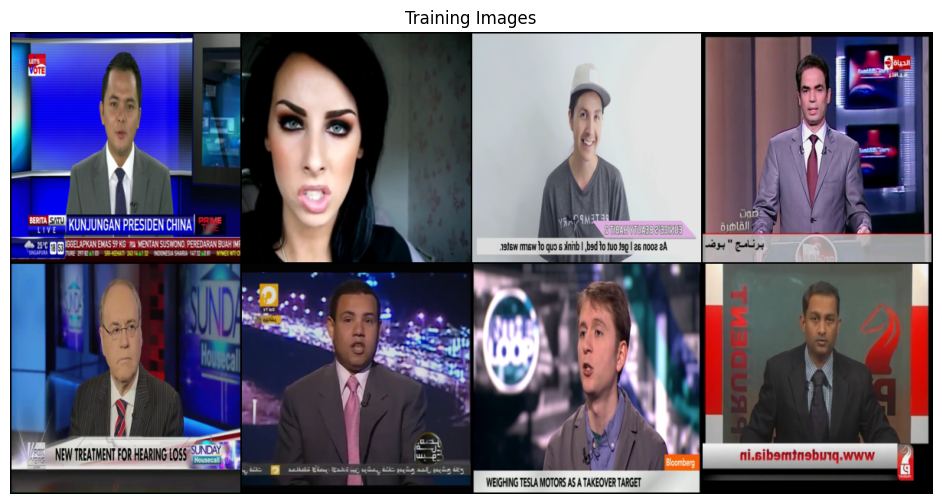

Labels: ['Real', 'Real', 'Fake', 'Real', 'Real', 'Real', 'Real', 'Fake']


In [16]:
import matplotlib.pyplot as plt
import torchvision

images, labels = next(iter(train_loader))

grid = torchvision.utils.make_grid(
    images[:8],
    nrow=4,
    normalize=True
)

plt.figure(figsize=(12, 6))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Training Images")
plt.show()

print("Labels:", [
    train_dataset.classes[label]
    for label in labels[:8]
])

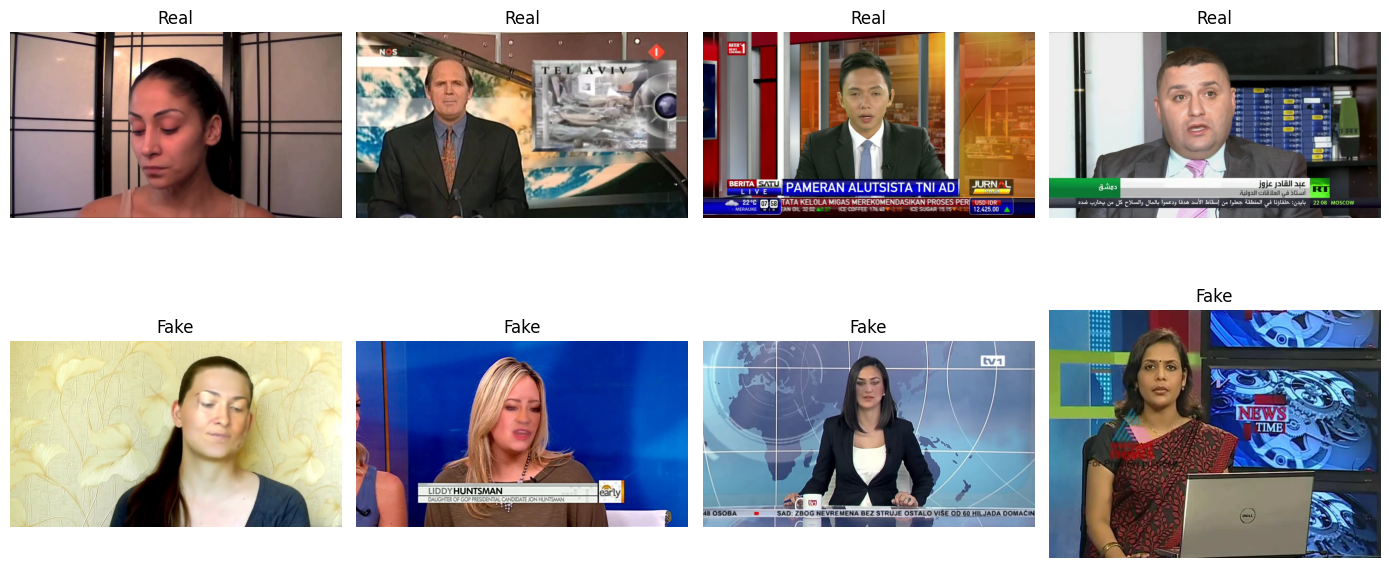

In [17]:
import matplotlib.pyplot as plt
import random

real_images = [
    f for f, label in train_dataset.samples
    if label == train_dataset.class_to_idx["Real"]
]

fake_images = [
    f for f, label in train_dataset.samples
    if label == train_dataset.class_to_idx["Fake"]
]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):
    real_img = train_dataset.loader(random.choice(real_images))
    fake_img = train_dataset.loader(random.choice(fake_images))

    axes[0, i].imshow(real_img)
    axes[0, i].set_title("Real")
    axes[0, i].axis("off")

    axes[1, i].imshow(fake_img)
    axes[1, i].set_title("Fake")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

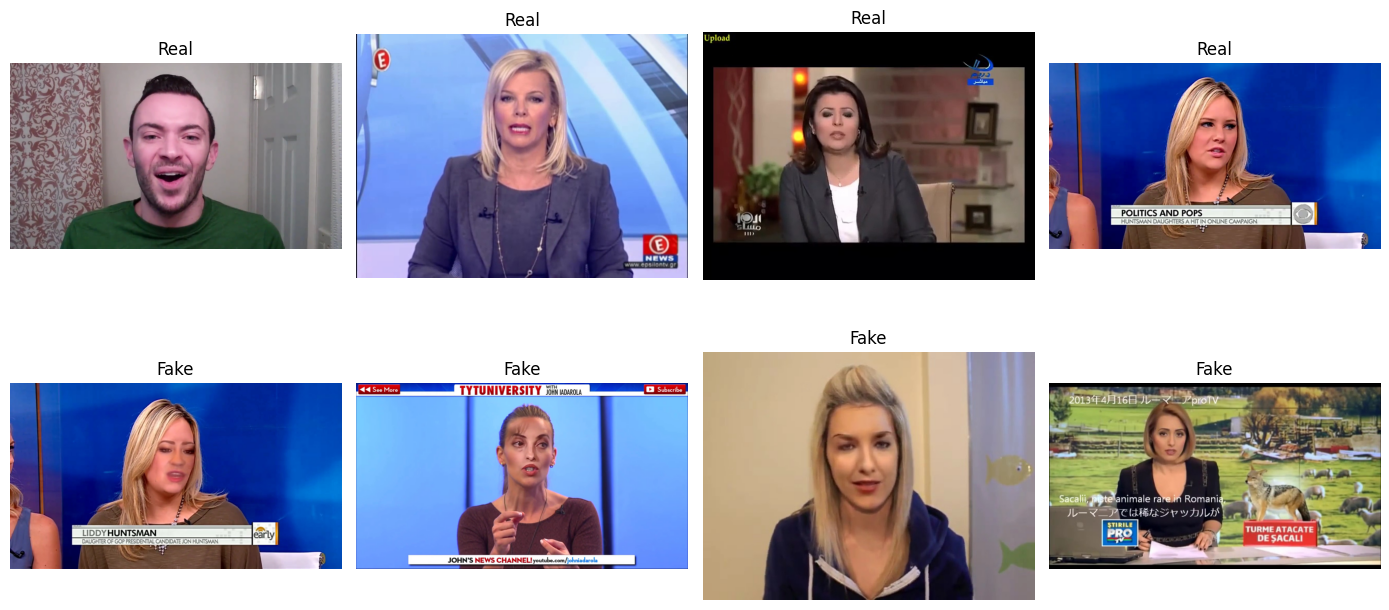

In [18]:
import matplotlib.pyplot as plt
import random

real_images = [
    f for f, label in train_dataset.samples
    if label == train_dataset.class_to_idx["Real"]
]

fake_images = [
    f for f, label in train_dataset.samples
    if label == train_dataset.class_to_idx["Fake"]
]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):
    real_img = train_dataset.loader(random.choice(real_images))
    fake_img = train_dataset.loader(random.choice(fake_images))

    axes[0, i].imshow(real_img)
    axes[0, i].set_title("Real")
    axes[0, i].axis("off")

    axes[1, i].imshow(fake_img)
    axes[1, i].set_title("Fake")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [19]:
import os
from collections import Counter

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for cls in ["Real", "Fake"]:
        folder = f"/kaggle/working/xception_data/{split}/{cls}"
        files = os.listdir(folder)

        video_ids = set()

        for filename in files:
            parts = filename.split("_")
            if cls == "Fake":
                video_ids.add(parts[0])
                video_ids.add(parts[1])
            else:
                video_ids.add(parts[0])

        print(
            cls,
            "| Images:", len(files),
            "| Video IDs:", len(video_ids)
        )


TRAIN
Real | Images: 350 | Video IDs: 285
Fake | Images: 350 | Video IDs: 282

VAL
Real | Images: 75 | Video IDs: 65
Fake | Images: 75 | Video IDs: 68

TEST
Real | Images: 75 | Video IDs: 67
Fake | Images: 75 | Video IDs: 59


In [20]:
import os

base = "/kaggle/working/xception_data"

def get_video_ids(split):
    ids = set()

    for cls in ["Real", "Fake"]:
        folder = os.path.join(base, split, cls)

        for filename in os.listdir(folder):
            parts = filename.split("_")

            ids.add(parts[0])

            if cls == "Fake" and len(parts) > 1:
                ids.add(parts[1])

    return ids

train_ids = get_video_ids("train")
val_ids = get_video_ids("val")
test_ids = get_video_ids("test")

print("Train-Val overlap:", len(train_ids & val_ids))
print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))

Train-Val overlap: 5
Train-Test overlap: 5
Val-Test overlap: 5


In [5]:
import os

print("Working directory:")
print(os.listdir("/kaggle/working"))

print("\nDataset folder exists:")
print(os.path.exists("/kaggle/working/xception_data"))

Working directory:
['.virtual_documents']

Dataset folder exists:
False


In [6]:
import os

print(os.listdir("/kaggle/input"))


['datasets']


In [7]:
import os

for root, dirs, files in os.walk("/kaggle/input/datasets"):
    print(root)
    if root.count(os.sep) >= 5:
        dirs.clear()

/kaggle/input/datasets
/kaggle/input/datasets/fatimahirshad
/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23


In [8]:
import os

path = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23"

print(os.listdir(path))

['CSVs', 'FF++C32-All-frames.csv', 'FF++C32-Frames']


In [9]:
import os

base = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23"

print("Dataset folders:")
print(os.listdir(os.path.join(base, "FF++C32-Frames")))

print("\nCSV files:")
print(os.listdir(os.path.join(base, "CSVs")))

Dataset folders:
['Deepfakes', 'Face2Face', 'FaceShifter', 'FaceSwap', 'NeuralTextures', 'Original']

CSV files:
['Deepfakes.csv', 'Face2Face.csv', 'FaceShifter.csv', 'FaceSwap.csv', 'NeuralTextures.csv', 'Original.csv']


In [10]:
import pandas as pd
import os

csv_path = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/CSVs"

for file in os.listdir(csv_path):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(csv_path, file))

        print("\nFile:", file)
        print("Columns:", df.columns.tolist())
        print(df.head(3))


File: Deepfakes.csv
Columns: ['filename', 'label', 'features', 'filepath', 'label_id']
         filename      label                           features  \
0  112_892_f0.jpg  Deepfakes  Manipulated face, synthetic frame   
1  546_621_f1.jpg  Deepfakes  Manipulated face, synthetic frame   
2  509_525_f4.jpg  Deepfakes  Manipulated face, synthetic frame   

                                            filepath  label_id  
0  /kaggle/input/faceforensics-extracted-dataset-...         2  
1  /kaggle/input/faceforensics-extracted-dataset-...         2  
2  /kaggle/input/faceforensics-extracted-dataset-...         2  

File: Face2Face.csv
Columns: ['filename', 'label', 'features', 'filepath', 'label_id']
         filename      label                                 features  \
0  163_031_f0.jpg  Face2Face  Face2Face manipulation, synthetic frame   
1  455_471_f1.jpg  Face2Face  Face2Face manipulation, synthetic frame   
2  347_314_f3.jpg  Face2Face  Face2Face manipulation, synthetic frame   

  

In [11]:
import pandas as pd
import os

csv_path = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/CSVs"

video_pairs = set()
all_video_ids = set()

for file in os.listdir(csv_path):
    if not file.endswith(".csv"):
        continue

    df = pd.read_csv(os.path.join(csv_path, file))

    for filename in df["filename"]:
        parts = filename.replace(".jpg", "").split("_")

        all_video_ids.add(parts[0])

        if len(parts) == 3:
            all_video_ids.add(parts[1])
            video_pairs.add((parts[0], parts[1]))

print("Total unique video IDs:", len(all_video_ids))
print("Total unique fake video pairs:", len(video_pairs))
print("\nSample video pairs:")
print(list(video_pairs)[:15])

Total unique video IDs: 1000
Total unique fake video pairs: 1000

Sample video pairs:
[('584', '823'), ('202', '348'), ('033', '097'), ('954', '976'), ('019', '018'), ('744', '674'), ('234', '187'), ('518', '131'), ('980', '992'), ('663', '231'), ('423', '421'), ('712', '716'), ('919', '015'), ('449', '451'), ('266', '252')]


In [12]:
import pandas as pd
import os
from collections import Counter

csv_path = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23/CSVs"

parent = {}

def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    ra = find(a)
    rb = find(b)
    if ra != rb:
        parent[ra] = rb

for file in os.listdir(csv_path):
    if file.endswith(".csv") and file != "Original.csv":
        df = pd.read_csv(os.path.join(csv_path, file))

        for filename in df["filename"]:
            parts = filename.replace(".jpg", "").split("_")

            if len(parts) == 3:
                union(parts[0], parts[1])

groups = {}

for video_id in parent:
    root = find(video_id)
    groups.setdefault(root, []).append(video_id)

sizes = sorted([len(v) for v in groups.values()], reverse=True)

print("Total connected groups:", len(groups))
print("Largest 10 group sizes:", sizes[:10])
print("Smallest group size:", sizes[-1])

Total connected groups: 500
Largest 10 group sizes: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Smallest group size: 2


In [13]:
import pandas as pd
import os

base = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23"

csv_path = os.path.join(base, "CSVs")
image_path = os.path.join(base, "FF++C32-Frames")

for category in [
    "Original", "Deepfakes", "Face2Face",
    "FaceShifter", "FaceSwap", "NeuralTextures"
]:
    df = pd.read_csv(os.path.join(csv_path, category + ".csv"))

    sample = df.iloc[0]["filename"]
    actual_path = os.path.join(image_path, category, sample)

    print(
        category,
        "| CSV images:", len(df),
        "| File exists:", os.path.exists(actual_path)
    )

Original | CSV images: 5000 | File exists: True
Deepfakes | CSV images: 5000 | File exists: True
Face2Face | CSV images: 5000 | File exists: True
FaceShifter | CSV images: 5000 | File exists: True
FaceSwap | CSV images: 5000 | File exists: True
NeuralTextures | CSV images: 5000 | File exists: True


In [2]:
import os
import pandas as pd
import random
import shutil

base = "/kaggle/input/datasets/fatimahirshad/faceforensics-extracted-dataset-c23"
csv_path = os.path.join(base, "CSVs")
image_path = os.path.join(base, "FF++C32-Frames")
output_path = "/kaggle/working/xception_data"

fake_methods = [
    "Deepfakes", "Face2Face", "FaceShifter",
    "FaceSwap", "NeuralTextures"
]

# 1. Build video groups
parent = {}

def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb

fake_data = {}

for method in fake_methods:
    df = pd.read_csv(os.path.join(csv_path, method + ".csv"))
    fake_data[method] = df

    for filename in df["filename"]:
        parts = filename[:-4].split("_")
        union(parts[0], parts[1])

groups = {}

for video_id in parent:
    groups.setdefault(find(video_id), set()).add(video_id)

group_list = list(groups.values())

print("Total groups:", len(group_list))

# 2. Split groups
random.seed(42)
random.shuffle(group_list)

splits = {
    "train": group_list[:350],
    "val": group_list[350:425],
    "test": group_list[425:500]
}

# 3. Create output folders
if os.path.exists(output_path):
    shutil.rmtree(output_path)

for split in splits:
    for cls in ["Real", "Fake"]:
        os.makedirs(os.path.join(output_path, split, cls))

# 4. Copy Real images
real_df = pd.read_csv(os.path.join(csv_path, "Original.csv"))

for split, selected_groups in splits.items():
    selected_ids = set().union(*selected_groups)

    for filename in real_df["filename"]:
        video_id = filename.split("_")[0]

        if video_id in selected_ids:
            src = os.path.join(image_path, "Original", filename)
            dst = os.path.join(output_path, split, "Real", filename)
            shutil.copyfile(src, dst)

# 5. Index fake images once
for method in fake_methods:
    df = fake_data[method]
    file_index = {}

    for filename in df["filename"]:
        parts = filename[:-4].split("_")

        if parts[2] == "f0":
            key = frozenset(parts[:2])
            file_index.setdefault(key, []).append(filename)

    # Copy fake images
    for split, selected_groups in splits.items():
        for group in selected_groups:
            key = frozenset(group)
            selected_files = file_index.get(key, [])

            if len(selected_files) != 2:
                raise ValueError(
                    f"{method}: Expected 2 images for {group}, "
                    f"found {len(selected_files)}"
                )

            for filename in selected_files:
                src = os.path.join(image_path, method, filename)
                dst_name = method + "__" + filename
                dst = os.path.join(output_path, split, "Fake", dst_name)
                shutil.copyfile(src, dst)

    print(method, "completed")

# 6. Display final counts
for split in splits:
    print("\n", split.upper())

    for cls in ["Real", "Fake"]:
        folder = os.path.join(output_path, split, cls)
        print(cls, ":", len(os.listdir(folder)))

print("\nDataset creation completed!")

Total groups: 500
Deepfakes completed
Face2Face completed
FaceShifter completed
FaceSwap completed
NeuralTextures completed

 TRAIN
Real : 3500
Fake : 3500

 VAL
Real : 750
Fake : 750

 TEST
Real : 750
Fake : 750

Dataset creation completed!


In [3]:
import os

base = "/kaggle/working/xception_data"

def get_video_ids(split):
    ids = set()

    for cls in ["Real", "Fake"]:
        folder = os.path.join(base, split, cls)

        for filename in os.listdir(folder):
            if "__" in filename:
                filename = filename.split("__", 1)[1]

            parts = filename.replace(".jpg", "").split("_")

            ids.add(parts[0])

            if cls == "Fake":
                ids.add(parts[1])

    return ids

train_ids = get_video_ids("train")
val_ids = get_video_ids("val")
test_ids = get_video_ids("test")

print("Train-Val overlap:", len(train_ids & val_ids))
print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [4]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

train_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])

test_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])

base = "/kaggle/working/xception_data"

train_dataset = datasets.ImageFolder(
    base + "/train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    base + "/val",
    transform=test_transform
)

test_dataset = datasets.ImageFolder(
    base + "/test",
    transform=test_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=32,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=32,
    shuffle=False, num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=32,
    shuffle=False, num_workers=2, pin_memory=True
)

print("Classes:", train_dataset.classes)
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Device: cuda
Classes: ['Fake', 'Real']
Train: 7000
Validation: 1500
Test: 1500


In [5]:
import timm
import torch.nn as nn

model = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=True,
    num_classes=2
)

model = model.to(device)

print("XceptionNet loaded successfully!")
print("Model:", type(model).__name__)
print("Device:", next(model.parameters()).device)

Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
XceptionNet loaded successfully!
Model: Xception
Device: cuda:0


In [6]:
import torch
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.00005,
    weight_decay=0.001
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Scheduler configured successfully!")

Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 5e-05
    maximize: False
    weight_decay: 0.001
)
Scheduler configured successfully!


In [7]:
import copy
import torch
import time

epochs = 15
patience = 5

best_val_loss = float("inf")
best_weights = copy.deepcopy(model.state_dict())
early_stop_counter = 0

for epoch in range(epochs):
    start_time = time.time()

    # Training
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = 100 * train_correct / train_total

    # Validation
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = 100 * val_correct / val_total

    scheduler.step(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.2f}% "
        f"Time: {time.time()-start_time:.1f}s"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        early_stop_counter = 0

        torch.save(best_weights, "/kaggle/working/best_xceptionnet.pth")
        print("Best model saved!")
    else:
        early_stop_counter += 1

    if early_stop_counter >= patience:
        print("Early stopping triggered!")
        break

model.load_state_dict(best_weights)
print("Training completed! Best validation loss:", best_val_loss)

Epoch [1/15] Train Loss: 0.6861 Train Acc: 54.10% Val Loss: 0.6615 Val Acc: 60.33% Time: 221.7s
Best model saved!
Epoch [2/15] Train Loss: 0.5706 Train Acc: 70.71% Val Loss: 0.6444 Val Acc: 63.27% Time: 243.4s
Best model saved!
Epoch [3/15] Train Loss: 0.4235 Train Acc: 80.60% Val Loss: 0.7550 Val Acc: 65.27% Time: 242.4s
Epoch [4/15] Train Loss: 0.3208 Train Acc: 86.73% Val Loss: 0.7472 Val Acc: 68.53% Time: 242.8s
Epoch [5/15] Train Loss: 0.2761 Train Acc: 88.67% Val Loss: 0.8964 Val Acc: 67.20% Time: 242.4s
Epoch [6/15] Train Loss: 0.2027 Train Acc: 92.11% Val Loss: 0.8914 Val Acc: 69.80% Time: 242.3s
Epoch [7/15] Train Loss: 0.1700 Train Acc: 93.19% Val Loss: 0.9527 Val Acc: 68.27% Time: 242.2s
Early stopping triggered!
Training completed! Best validation loss: 0.6443838585217794


In [8]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

        # Fake is class 0
        all_probabilities.extend(probabilities[:, 0].cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)

print("XceptionNet Test Results")
print("------------------------")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Fake", "Real"]
))

auc = roc_auc_score(
    np.array(all_labels) == 0,
    all_probabilities
)

print(f"ROC-AUC Score: {auc:.4f}")

XceptionNet Test Results
------------------------
Test Accuracy: 63.47%

Confusion Matrix:
[[591 159]
 [389 361]]

Classification Report:
              precision    recall  f1-score   support

        Fake       0.60      0.79      0.68       750
        Real       0.69      0.48      0.57       750

    accuracy                           0.63      1500
   macro avg       0.65      0.63      0.63      1500
weighted avg       0.65      0.63      0.63      1500

ROC-AUC Score: 0.6966


In [9]:
import torch.nn as nn

print("Last convolution layers in XceptionNet:\n")

conv_layers = []

for name, layer in model.named_modules():
    if isinstance(layer, nn.Conv2d):
        conv_layers.append(name)

for name in conv_layers[-10:]:
    print(name)

Last convolution layers in XceptionNet:

block11.rep.7.pointwise
block12.skip
block12.rep.1.conv1
block12.rep.1.pointwise
block12.rep.4.conv1
block12.rep.4.pointwise
conv3.conv1
conv3.pointwise
conv4.conv1
conv4.pointwise


In [10]:
total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Trainable Percentage:",
      round(trainable_params / total_params * 100, 2), "%")

Total Parameters: 20811050
Trainable Parameters: 20811050
Trainable Percentage: 100.0 %


Actual Class: Fake
Predicted Class: Fake


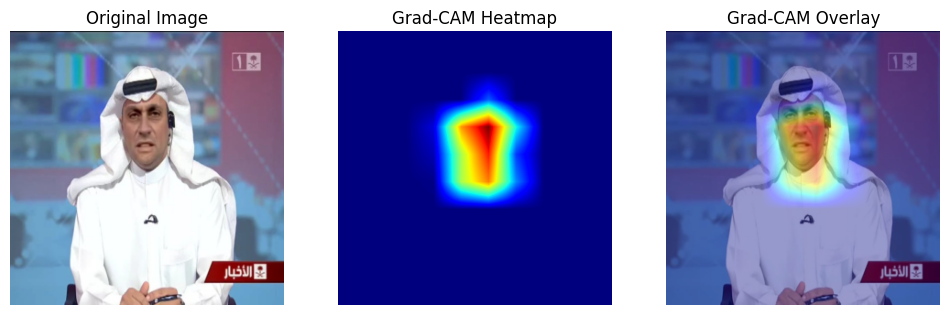

In [11]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

model.eval()

target_layer = model.conv4.pointwise

activations = []
gradients = []

def forward_hook(module, input, output):
    activations.append(output)
    output.register_hook(lambda grad: gradients.append(grad))

handle = target_layer.register_forward_hook(forward_hook)

# Get one test image
images, labels = next(iter(test_loader))
image = images[0:1].to(device)

model.zero_grad()

# Forward pass
output = model(image)
predicted_class = output.argmax(dim=1).item()

# Backward pass
score = output[0, predicted_class]
score.backward()

# Generate Grad-CAM
activation = activations[0].detach()
gradient = gradients[0].detach()

weights = gradient.mean(dim=(2, 3), keepdim=True)
cam = (weights * activation).sum(dim=1, keepdim=True)
cam = F.relu(cam)

cam = F.interpolate(
    cam,
    size=(299, 299),
    mode="bilinear",
    align_corners=False
)

cam = cam[0, 0].cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

# Original image
original = image[0].detach().cpu()
original = original * 0.5 + 0.5
original = original.permute(1, 2, 0).numpy()

# Display
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original)
plt.imshow(cam, cmap="jet", alpha=0.4)
plt.title("Grad-CAM Overlay")
plt.axis("off")

class_names = ["Fake", "Real"]
print("Actual Class:", class_names[labels[0].item()])
print("Predicted Class:", class_names[predicted_class])

plt.show()

handle.remove()

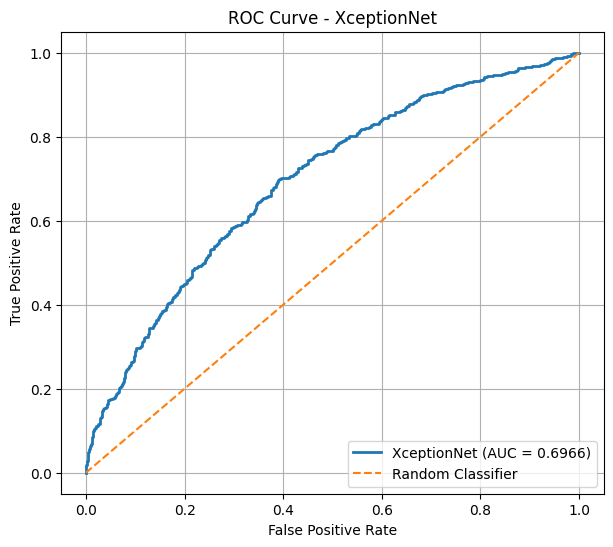

ROC-AUC: 0.6966


In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Fake class = 0
y_true = np.array(all_labels)
y_scores = np.array(all_probabilities)

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(
    y_true == 0,
    y_scores
)

roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"XceptionNet (AUC = {roc_auc:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XceptionNet")
plt.legend(loc="lower right")
plt.grid()
plt.show()

print("ROC-AUC:", round(roc_auc, 4))

In [13]:
import torch
import json

# Save trained model
torch.save(
    model.state_dict(),
    "/kaggle/working/XceptionNet_Final.pth"
)

# Save evaluation results
results = {
    "Model": "XceptionNet",
    "Training Accuracy": 93.19,
    "Validation Accuracy": 69.80,
    "Test Accuracy": 63.47,
    "Precision": 0.60,
    "Recall": 0.79,
    "F1 Score": 0.68,
    "ROC-AUC": 0.6966
}

with open("/kaggle/working/XceptionNet_Results.json", "w") as f:
    json.dump(results, f, indent=4)

print("XceptionNet model and results saved successfully!")

XceptionNet model and results saved successfully!


In [15]:
import zipfile
import os

files_to_save = [
    "XceptionNet_Final.pth",
    "XceptionNet_Results.json",
    "best_xceptionnet.pth"
]

zip_path = "/kaggle/working/XceptionNet_Project.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_save:
        file_path = os.path.join("/kaggle/working", file)

        if os.path.exists(file_path):
            zipf.write(file_path, arcname=file)
            print("Added:", file)
        else:
            print("Not found:", file)

print("\nZIP created:", os.path.exists(zip_path))
print("ZIP size:", os.path.getsize(zip_path) / (1024**2), "MB")

Added: XceptionNet_Final.pth
Added: XceptionNet_Results.json
Added: best_xceptionnet.pth

ZIP created: True
ZIP size: 147.91713428497314 MB


In [16]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/XceptionNet_Project.zip"))

/kaggle/working/XceptionNet_Project.zip

In [ ]:
from IPython.display import display, HTML
import base64

zip_path = "/kaggle/working/XceptionNet_Project.zip"

with open(zip_path, "rb") as f:
    data = base64.b64encode(f.read()).decode()

display(HTML(
    f'<a download="XceptionNet_Project.zip" '
    f'href="data:application/zip;base64,{data}">'
    f'Click here to download XceptionNet ZIP</a>'
))